In [1]:

import pandas as pd

# Load the customer dataset
df = pd.read_csv("data/Telco-Customer-Churn.csv")

# Check its dimensions
print("Dataset shape:", df.shape)

# Display the first 5 customers
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Display all column names
print(df.columns.tolist())

# Check data types
print(df.dtypes)

# Check missing values
print(df.isnull().sum())


['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
customerID          0
gender              0
SeniorCitizen       0
Partner 

In [3]:

# Convert to numeric temporarily, without changing df
charges = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Count values that could not be converted
print("Invalid values:", charges.isna().sum())


Invalid values: 11


In [4]:

# Show customers with invalid TotalCharges
df[charges.isna()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:

# 1. Convert TotalCharges into numbers
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# 2. Replace missing values with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 3. Verify the result
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())


Data type: float64
Missing values: 0


In [6]:

# Count customers who stayed vs. left
print(df["Churn"].value_counts())

# Calculate percentages
print(df["Churn"].value_counts(normalize=True) * 100)


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


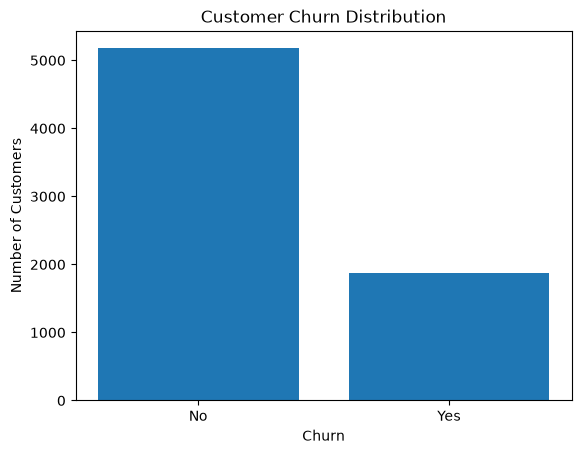

In [7]:

import matplotlib.pyplot as plt

# Count customers by churn category
churn_counts = df["Churn"].value_counts()

# Create bar chart
plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()


In [8]:

# Calculate average tenure for each churn group
average_tenure = df.groupby("Churn")["tenure"].mean()

print(average_tenure)


Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [9]:

# Compare average monthly charges
average_charges = df.groupby("Churn")["MonthlyCharges"].mean()

print(average_charges)


Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [10]:

# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))


Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [11]:

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))


Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


In [12]:

# Average monthly bill by internet service
service_charges = df.groupby("InternetService")["MonthlyCharges"].mean()

print(service_charges.round(2))


InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64


In [13]:

# Calculate churn rate by payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))


Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11

In [14]:

# Check duplicate customer IDs
print("Duplicate customers:", df["customerID"].duplicated().sum())

# Check duplicate complete rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate customers: 0
Duplicate rows: 0


In [15]:

# X contains the information used for prediction
X = df.drop(columns=["customerID", "Churn"])

# y contains what we want to predict
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (7043, 19)
Target shape: (7043,)


In [16]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

# Identify categorical columns
categorical_cols = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)



Training: (5634, 19)
Testing: (1409, 19)
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [17]:

from sklearn.preprocessing import OneHotEncoder

# Create our encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Learn categories from training data and encode them
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

print("Encoded shape:", X_train_encoded.shape)


Encoded shape: (5634, 41)


In [18]:

# Get the names of the encoded features
encoded_names = encoder.get_feature_names_out(categorical_cols)

# Display the first 15 names
print(encoded_names[:15])

# Display the first customer's encoded values
print(X_train_encoded[0][:15])


['gender_Female' 'gender_Male' 'Partner_No' 'Partner_Yes' 'Dependents_No'
 'Dependents_Yes' 'PhoneService_No' 'PhoneService_Yes' 'MultipleLines_No'
 'MultipleLines_No phone service' 'MultipleLines_Yes'
 'InternetService_DSL' 'InternetService_Fiber optic' 'InternetService_No'
 'OnlineSecurity_No']
[0. 1. 1. 0. 1. 0. 1. 0. 0. 1. 0. 1. 0. 0. 1.]


In [19]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),

        ("numerical",
         StandardScaler(),
         numerical_cols)
    ]
)

print("Updated preprocessor created!")



Updated preprocessor created!


In [20]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create our complete ML pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [21]:

from sklearn.metrics import accuracy_score, classification_report

# Predict churn for test customers
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

# Display detailed evaluation metrics
print(classification_report(y_test, y_pred))


Accuracy: 80.55 %
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



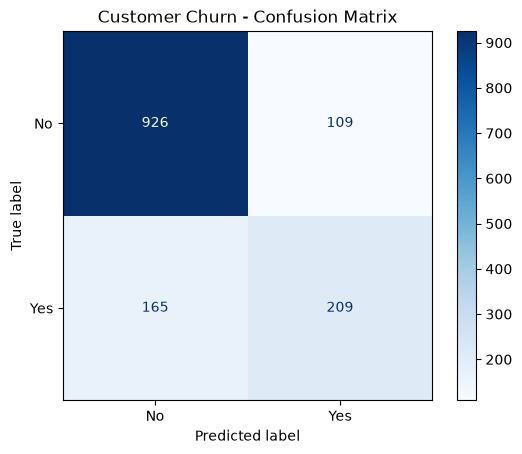

In [22]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Customer Churn - Confusion Matrix")
plt.show()


In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a separate Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [24]:

from sklearn.metrics import accuracy_score, classification_report

# Random Forest predictions
rf_pred = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

# Detailed performance
print(classification_report(y_test, rf_pred))


Random Forest Accuracy: 78.78 %
              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [25]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [1, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="recall_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV macro recall:", round(grid_search.best_score_, 3))


Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1}
Best CV macro recall: 0.708


In [26]:

from sklearn.metrics import accuracy_score, classification_report

# Get the best tuned Random Forest
best_rf = grid_search.best_estimator_

# Predict on the test set
best_rf_pred = best_rf.predict(X_test)

# Evaluate
print("Tuned Random Forest Accuracy:",
      round(accuracy_score(y_test, best_rf_pred) * 100, 2), "%")

print(classification_report(y_test, best_rf_pred))


Tuned Random Forest Accuracy: 80.13 %
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [27]:

import numpy as np
from sklearn.metrics import precision_score, recall_score

# Probability that each customer will leave
churn_index = list(model.classes_).index("Yes")
churn_probabilities = model.predict_proba(X_test)[:, churn_index]

# Compare different thresholds
for threshold in [0.5, 0.4, 0.3]:
    predictions = np.where(
        churn_probabilities >= threshold, "Yes", "No"
    )

    precision = precision_score(
        y_test, predictions, pos_label="Yes"
    )
    recall = recall_score(
        y_test, predictions, pos_label="Yes"
    )

    print(f"Threshold: {threshold}")
    print(f"Churn Precision: {precision:.2f}")
    print(f"Churn Recall: {recall:.2f}")
    print("--------------------")


Threshold: 0.5
Churn Precision: 0.66
Churn Recall: 0.56
--------------------
Threshold: 0.4
Churn Precision: 0.57
Churn Recall: 0.67
--------------------
Threshold: 0.3
Churn Precision: 0.52
Churn Recall: 0.75
--------------------


In [28]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Use the probabilities we calculated earlier
threshold = 0.40

final_predictions = np.where(
    churn_probabilities >= threshold,
    "Yes",
    "No"
)

print(classification_report(y_test, final_predictions))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    final_predictions,
    labels=["No", "Yes"]
))


              precision    recall  f1-score   support

          No       0.87      0.82      0.84      1035
         Yes       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion Matrix:
[[845 190]
 [124 250]]


In [29]:
import joblib

# Save the trained pipeline
joblib.dump(model, "models/churn_model.pkl")

# Save our provisional decision threshold
joblib.dump(0.40, "models/churn_threshold.pkl")

print("Model and threshold saved successfully!")

Model and threshold saved successfully!


In [30]:

import joblib
import numpy as np

# Load our saved model and threshold
loaded_model = joblib.load("models/churn_model.pkl")
loaded_threshold = joblib.load("models/churn_threshold.pkl")

# Take one customer from our test data
new_customer = X_test.iloc[[0]]

# Predict the probability of leaving
churn_index = list(loaded_model.classes_).index("Yes")
probability = loaded_model.predict_proba(new_customer)[0, churn_index]

# Apply our saved threshold
prediction = "Yes" if probability >= loaded_threshold else "No"

print("Churn probability:", round(probability * 100, 2), "%")
print("Predicted churn:", prediction)
print("Actual churn:", y_test.iloc[0])


Churn probability: 4.59 %
Predicted churn: No
Actual churn: No


In [31]:

import joblib
import numpy as np

# Load our saved model and threshold
loaded_model = joblib.load("models/churn_model.pkl")
loaded_threshold = joblib.load("models/churn_threshold.pkl")

# Take one customer from our test data
new_customer = X_test.iloc[[0]]

# Predict the probability of leaving
churn_index = list(loaded_model.classes_).index("Yes")
probability = loaded_model.predict_proba(new_customer)[0, churn_index]

# Apply our saved threshold
prediction = "Yes" if probability >= loaded_threshold else "No"

print("Churn probability:", round(probability * 100, 2), "%")
print("Predicted churn:", prediction)
print("Actual churn:", y_test.iloc[0])


Churn probability: 4.59 %
Predicted churn: No
Actual churn: No


In [32]:
import joblib

model = joblib.load("models/churn_model.pkl")
threshold = joblib.load("models/churn_threshold.pkl")

print("Model loaded successfully!")
print("Threshold:", threshold)

Model loaded successfully!
Threshold: 0.4


In [33]:
# Step 51: Verify the reloaded model

probability = model.predict_proba(
    X_test.iloc[[0]]
)[0][1]

prediction = "Yes" if probability >= threshold else "No"

print("Churn probability:", round(probability * 100, 2), "%")
print("Predicted churn:", prediction)
print("Actual churn:", y_test.iloc[0])

Churn probability: 4.59 %
Predicted churn: No
Actual churn: No


In [34]:
# Step 52: Test multiple customers

customers = X_test.iloc[:10]

probabilities = model.predict_proba(customers)[:, 1]

predictions = [
    "Yes" if p >= threshold else "No"
    for p in probabilities
]

results = pd.DataFrame({
    "Churn Probability": probabilities.round(3),
    "Predicted Churn": predictions,
    "Actual Churn": y_test.iloc[:10].values
})

display(results)

,Churn Probability,Predicted Churn,Actual Churn
0,0.046,No,No
1,0.684,Yes,No
2,0.059,No,No
3,0.402,Yes,No
4,0.021,No,No
5,0.603,Yes,No
6,0.448,Yes,No
7,0.130,No,No
8,0.003,No,No
9,0.395,No,Yes


In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    results["Actual Churn"],
    results["Predicted Churn"]
)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 50.0 %


In [36]:
# Check each prediction

results["Correct"] = (
    results["Predicted Churn"] == results["Actual Churn"]
)

display(results)

print("Correct predictions:", results["Correct"].sum())
print("Total customers:", len(results))
print("Accuracy:", results["Correct"].mean() * 100, "%")

,Churn Probability,Predicted Churn,Actual Churn,Correct
0,0.046,No,No,True
1,0.684,Yes,No,False
2,0.059,No,No,True
3,0.402,Yes,No,False
4,0.021,No,No,True
5,0.603,Yes,No,False
6,0.448,Yes,No,False
7,0.130,No,No,True
8,0.003,No,No,True
9,0.395,No,Yes,False


Correct predictions: 5
Total customers: 10
Accuracy: 50.0 %


In [37]:
from sklearn.metrics import accuracy_score

# Predict probabilities for ALL test customers
all_probabilities = model.predict_proba(X_test)[:, 1]

# Apply our saved threshold
all_predictions = [
    "Yes" if p >= threshold else "No"
    for p in all_probabilities
]

# Calculate accuracy
full_accuracy = accuracy_score(y_test, all_predictions)

print("Total test customers:", len(X_test))
print("Correct predictions:",
      sum(y_test.values == all_predictions))
print("Full test accuracy:",
      round(full_accuracy * 100, 2), "%")

Total test customers: 1409
Correct predictions: 1095
Full test accuracy: 77.71 %


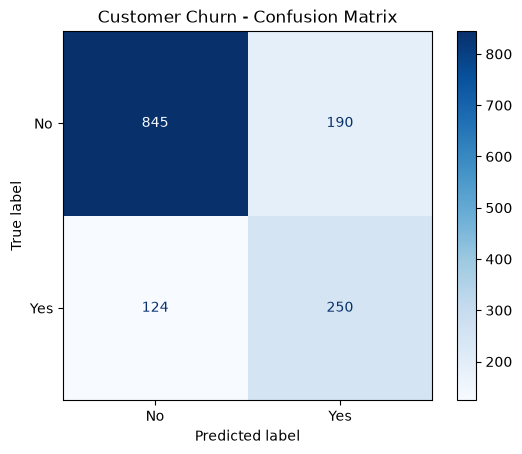

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    all_predictions,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Customer Churn - Confusion Matrix")
plt.show()

In [39]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    all_predictions,
    labels=["No", "Yes"],
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.87      0.82      0.84      1035
         Yes       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Thresholds we want to compare
thresholds = [0.3, 0.4, 0.5, 0.6]

comparison = []

for t in thresholds:

    # Apply the threshold to predicted probabilities
    preds = [
        "Yes" if p >= t else "No"
        for p in all_probabilities
    ]

    # Calculate performance metrics
    comparison.append({
        "Threshold": t,
        "Precision": precision_score(
            y_test, preds, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test, preds, pos_label="Yes"
        ),
        "F1-score": f1_score(
            y_test, preds, pos_label="Yes"
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Threshold,Precision,Recall,F1-score
0,0.3,0.519,0.754,0.615
1,0.4,0.568,0.668,0.614
2,0.5,0.657,0.559,0.604
3,0.6,0.718,0.401,0.515


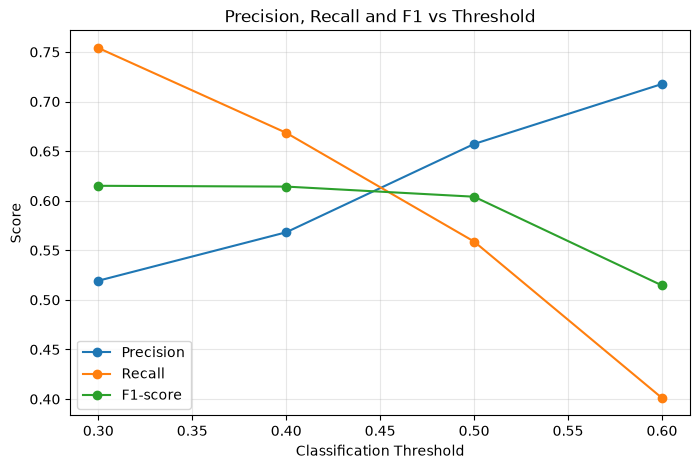

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["Threshold"],
    comparison_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    comparison_df["Threshold"],
    comparison_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    comparison_df["Threshold"],
    comparison_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:

comparison_df.to_csv(
    "results/threshold_comparison.csv",
    index=False
)

print("Threshold comparison saved successfully!")

Threshold comparison saved successfully!


In [43]:
from pathlib import Path

files = [
    "data/Telco-Customer-Churn.csv",
    "models/churn_model.pkl",
    "models/churn_threshold.pkl",
    "results/threshold_comparison.csv"
]

for file in files:
    print(file, ":", Path(file).exists())

data/Telco-Customer-Churn.csv : True
models/churn_model.pkl : True
models/churn_threshold.pkl : True
results/threshold_comparison.csv : True


In [44]:
import joblib

loaded_model = joblib.load("models/churn_model.pkl")
loaded_threshold = joblib.load("models/churn_threshold.pkl")

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)

Model loaded successfully!
Threshold: 0.4


In [45]:
probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[0][1]

prediction = (
    "Yes" if probability >= loaded_threshold else "No"
)

print("Churn probability:", round(probability * 100, 2), "%")
print("Predicted churn:", prediction)

Churn probability: 4.59 %
Predicted churn: No


In [46]:
print("Model type:", type(model))
print("Loaded model type:", type(loaded_model))

Model type: <class 'sklearn.pipeline.Pipeline'>
Loaded model type: <class 'sklearn.pipeline.Pipeline'>


In [47]:
print(loaded_model.steps)

[('preprocessor', ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod']),
                                ('numerical', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges'])])), ('classifier', LogisticRegression(max_iter=1000))]


In [48]:
import joblib
import numpy as np

final_model = joblib.load("models/churn_model.pkl")
final_threshold = joblib.load("models/churn_threshold.pkl")

same = np.allclose(
    model.predict_proba(X_test),
    final_model.predict_proba(X_test)
)

print("Model predictions match:", same)
print("Saved threshold:", final_threshold)

Model predictions match: True
Saved threshold: 0.4
